In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
os.environ["KERAS_BACKEND"] = "torch"

import src.util.supabase_utils as su
import src.config as config
import src.data_preprocessing.text_preprocessing as text_pre
from src.data_preprocessing.TextEmbedder import TextEmbedder
from src.agents.util.Retriever import Retriever
from src.agents.util.ResponseModel import ResponseModel
from src.agents.NLP_Agent import NLPAgent
from src.agents.Visual_Agent import VisualModel
import src.data_preprocessing.image_preprocessing as img_pre
import keras
import numpy as np
import bert_score
import sacrebleu
import pandas as pd
import time
import matplotlib.pyplot as plt
import src.data_preprocessing.text_data_exploration as de


I0000 00:00:1792024943.613790   39925 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792024944.724767   39925 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:

plant_expert_vqa_TRAIN= text_pre.load_csv(config.Data.PlantExpertVQA.TRAIN_FILE)
plant_expert_vqa_TEST= text_pre.load_csv(config.Data.PlantExpertVQA.TEST_FILE)
plant_expert_vqa_VAL= text_pre.load_csv(config.Data.PlantExpertVQA.VALIDATION_FILE)

# training

text_pre.preprocess_dataframe(
    plant_expert_vqa_TRAIN,
    config.Data.PlantExpertVQA.TEXT_COLUMNS,
    config.Data.PlantExpertVQA.COLUMNS_TO_REMOVE,
    config.Data.PlantExpertVQA.NA_FILL,
    ["image_path"],
    config.Data.PlantExpertVQA.ROOT,
)

# testing
text_pre.preprocess_dataframe(
    plant_expert_vqa_TEST,
    config.Data.PlantExpertVQA.TEXT_COLUMNS,
    config.Data.PlantExpertVQA.COLUMNS_TO_REMOVE,
    config.Data.PlantExpertVQA.NA_FILL,
    ["image_path"],
    config.Data.PlantExpertVQA.ROOT,
)

#validation
text_pre.preprocess_dataframe(
    plant_expert_vqa_VAL,
    config.Data.PlantExpertVQA.TEXT_COLUMNS,
    config.Data.PlantExpertVQA.COLUMNS_TO_REMOVE,
    config.Data.PlantExpertVQA.NA_FILL,
    ["image_path"],
    config.Data.PlantExpertVQA.ROOT,
)

17:42:27 [DEBUG   ]: [load_csv] Successfully loaded /home/chris/capstone/PlantQA/data/PlantExpertVQA/data/train.csv into dataframe


/home/chris/capstone/PlantQA/src/data_preprocessing/text_preprocessing.py:44: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  data= pd.read_csv(csv_path)


17:42:27 [DEBUG   ]: [load_csv] Successfully loaded /home/chris/capstone/PlantQA/data/PlantExpertVQA/data/test.csv into dataframe
17:42:27 [DEBUG   ]: [load_csv] Successfully loaded /home/chris/capstone/PlantQA/data/PlantExpertVQA/data/val.csv into dataframe


In [3]:
embedder = TextEmbedder("sentence-transformers/all-MiniLM-L6-v2")
client = su.connect_supabase()
scorer = bert_score.BERTScorer(
    model_type="roberta-large",
    lang="en",
    rescale_with_baseline=False,
)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

https://xpaeosksmgrhvgxtyloz.supabase.co
sb_secret__ntLGQpwwr09Bvx55e7igA_AxvdNijF


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [4]:
retriever = Retriever(client, embedder, match_threshold=.5)
unet = keras.models.load_model("models/unet_models/UNet_Best.keras", compile=False)
visual_model = VisualModel.load("models/visual_models/10_11.keras", "models/visual_models/10_11_classes.json", unet=unet)
response_model = ResponseModel(adapter="models/response_models/10_9")
agent = NLPAgent(retriever=retriever, response_model=response_model, visual_model=visual_model)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

In [5]:

def cosine_similarity(pred_a, label_a):
    embed_pred_a= embedder.encode(pred_a)
    embed_label_a= embedder.encode(label_a)

    pred= np.asarray(embed_pred_a, dtype=np.float32)
    label= np.asarray(embed_label_a, dtype=np.float32)

    denominator= np.linalg.norm(pred) * np.linalg.norm(label)

    if denominator:
        similarity= float(np.dot(pred, label) / denominator)
    else:
        similarity= 0.0

    return similarity

def bert_similarity(pred_a, label_a):
    precision, recall, f1= scorer.score(
        [pred_a],
        [label_a],
    )

    return {
        "precision": precision.item(),
        "recall": recall.item(),
        "f1": f1.item()
    }

def bleu_score(pred_a, label_a):
    bleu= sacrebleu.sentence_bleu(pred_a, [label_a])
    return bleu.score

def evaluate(question, pred_a, label_a):
    cosine_sim= cosine_similarity(pred_a, label_a)
    bert= bert_similarity(pred_a, label_a)
    bleu= bleu_score(pred_a, label_a)
    results= {
        "question": question,
        "label": label_a,
        "prediction": pred_a,
        "cosine_similarity": cosine_sim,
        "bert_precision": bert["precision"],
        "bert_recall": bert["recall"],
        "bert_f1": bert["f1"],
        "bleu_score": bleu,
    }
    return results

In [6]:
results=[]
index = 1
total_start = time.perf_counter()

for row in plant_expert_vqa_TEST.sample(20, random_state=0).itertuples():
    

    image = img_pre.load_image(row.image_path)
    question=row.question_text

    print(type(image))
    print(image.shape)

    prediction = visual_model.predict(image)
    visual_predictions = prediction.get_observations()
    question_embedding = retriever.retrieve(
            f"{question} {visual_predictions}" if visual_predictions else question,
            plant_code_filter = prediction.get_plant_code() if prediction else plant_code_filter,
            genus_filter = prediction.get_genus() if prediction else None,
            num_results = 5)

    answer = response_model.generate_answer(question = question, chunks = question_embedding, visual_predictions = visual_predictions)

    
    #answer = agent.ask_question(image=image, question=row.question_text)

    run_start = time.perf_counter()
    
    result = evaluate(question, answer, row.answer)
    
    run_time = time.perf_counter() - run_start
    result["runtime"]= run_time
    
    results.append(result)
    if index % 100 == 0:
        print(f"Test {index} completed in {run_time:.2f} seconds")

    index += 1


<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(256, 256, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(256, 256, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(256, 256, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(1024, 1024, 3)
<class 'numpy.ndarray'>
(256, 256, 3)


In [7]:

data= pd.DataFrame(results)

data["question_lengths"]= data["question"].str.len()
data["label_lengths"]= data["label"].str.len()
data["prediction_lengths"]= data["prediction"].str.len()

print(data.head())
print("\n\n\n")
print(f"Description:\n\n")
print(data.describe())
print("\n\n\n")
print(data["prediction"][0])
print()
print(data["prediction"][1])
print()

print(data["prediction"][2])
print()

print(data["prediction"][3])
print()

print(data["prediction"][4])

                                            question  \
0  What conditions led to this late blight infect...   
1  Can this leaf be categorized as pathogen-infec...   
2                        What disease is shown here?   
3  Could this be leaf scald instead? How do you d...   
4  What formal diagnosis would you assign to thes...   

                                               label  \
0  late blight developed due to high humidity and...   
1                                                Yes   
2  This is anthracnose, displaying severe symptom...   
3  This is bacterial leaf blight, not leaf scald....   
4  This is Late Blight, caused by the oomycete Ph...   

                                          prediction  cosine_similarity  \
0  Late blight due to wet conditions and high hum...           0.748424   
1  This leaf shows symptoms of late blight, inclu...           0.053210   
2  This is Anthracnose, displaying severe symptom...           0.869429   
3  This is Bacterial Leaf 

In [8]:

def make_boxplot(pred_lengths, label_lengths):
    plt.boxplot([label_lengths, pred_lengths],tick_labels=["Label Length", "Prediction Length"])
    plt.ylabel("Text Length")
    plt.title("Label and Prediction Length Boxplot")
    plt.show()

def make_scatterplot(q_lengths, pred_lengths):
    plt.scatter(q_lengths, pred_lengths, alpha=0.5)
    plt.xlabel("Question Length")
    plt.ylabel("Prediction Length")
    plt.title("Question and Prediction Length Scatterplot")
    plt.grid(True, alpha=0.3)
    plt.show()

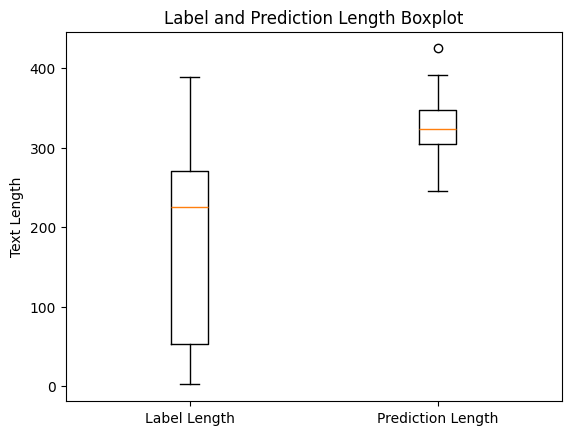

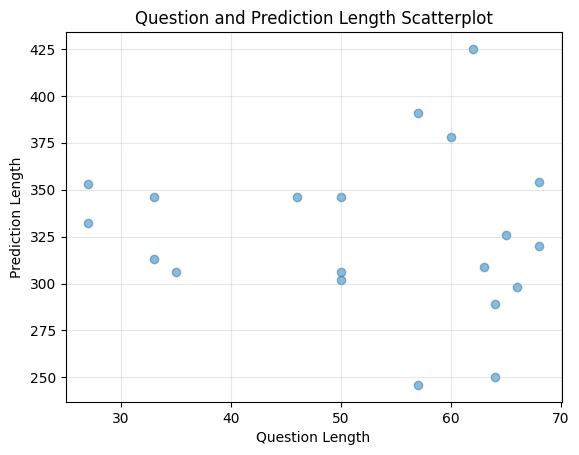

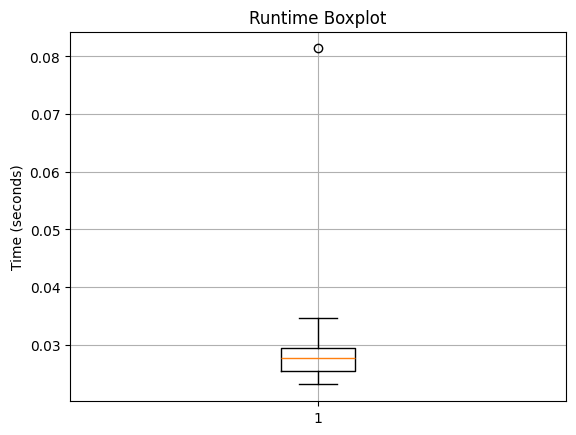

In [9]:
pred_lengths= data["prediction_lengths"].dropna()
lab_lengths= data["label_lengths"].dropna()
q_lengths= data["question_lengths"].dropna()

make_boxplot(pred_lengths, lab_lengths)
make_scatterplot(q_lengths, pred_lengths)
de.make_box_plot(data["runtime"], "Time (seconds)", title="Runtime Boxplot")